In [54]:
%load_ext autoreload
%autoreload 2
import jax.numpy as jnp
import jax_sn

import jax_sbgeom as jsb
import jax
import matplotlib.pyplot as plt
import numpy as onp
import equinox as eqx
jax.config.update("jax_enable_x64", True)
from jax_sbgeom.flux_surfaces import FluxSurfaceNormalExtendedNoPhi, ToroidalExtent, FluxSurface
from jax_sn.tools.memory_analysis import _filter_jit_f_to_memory
vmec_file = ["/home/tbogaarts/stellarator_paper/base_data/vmecs/helias5_vmec.nc4"][0]
fs_base = FluxSurfaceNormalExtendedNoPhi.from_hdf5(vmec_file)
from functools import partial
import pyvista as pv
from jax_sbgeom.jax_utils import mesh_to_pyvista_mesh
import lineax as lx
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver, MultiGroupOperatorScanCheckpoint
from typing import Tuple, Callable
from dataclasses import dataclass


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from breeding_blanket_setup import _get_bb_args, _setup_bb_args

In [114]:
dim = 1 
degree = 7
dim, degree, d_elem_regions, n_elem_regions, d_other_dim, n_other_dim, tn_order = _get_bb_args(dim, degree)
print(n_elem_regions)
MGOP, source_total, solution_domain = _setup_bb_args(dim, degree, d_elem_regions, n_elem_regions, d_other_dim, n_other_dim, tn_order)

#eqx.tree_at(lambda x : x.transport_operator.transport_operator,)

[5, 1, 1, 5, 5, 1, 5, 2]


In [107]:
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver, MultiGroupOperator

from jax_sn.parametrisation.multigroup_parametrisation import MultigroupOperatorParametrisedVertices, MultigroupOperatorParametrisedObjective

from jax_sn.tools.parametrisation_tools import ParametrisedModule, ParametrisationValues, ParametrisedModuleTheta

In [108]:
from jax_sn.operators.transport_operator import TransportOperatorVmapPallas, TransportOperatorMultipleAnglesVmap

pallas_op = TransportOperatorMultipleAnglesVmap(TransportOperatorVmapPallas(MGOP.transport_operator.transport_operator.solution_domain_data, MGOP.transport_operator.transport_operator.topological_sorted_angle, 0))
MGOPcp    = MultiGroupOperatorScanCheckpoint(MGOP.moment_operator, MGOP.discrete_operator, pallas_op, MGOP.mass_operator, MGOP.gather_scatter_operator, MGOP.n_energy_groups, MGOP.transpose_bool)

In [109]:
class BZShieldValues(ParametrisationValues):
    bzshield : jnp.ndarray

class BZShieldSettings(eqx.Module):
    resolution_layers : Tuple[int]
    base_layer_size   : jnp.ndarray
    

@partial(jax.jit, static_argnums = 1)
def create_vertices(size_layers, resolution_layers):
    n_regions_dim= size_layers.shape[0]
    cumsum_nodes  = jnp.concatenate([jnp.array([0]), jnp.cumsum(size_layers)])        
    return jnp.concatenate([jnp.linspace(cumsum_nodes[i], cumsum_nodes[i+1], resolution_layers[i], endpoint=False) for i in range(n_regions_dim)] + [jnp.array([cumsum_nodes[-1]])])

@eqx.filter_jit
def create_bzshield_vertices(params : BZShieldValues, settings : BZShieldSettings):
    bzshield = params.bzshield
    resolution_layers = settings.resolution_layers
    base_layer_size   = settings.base_layer_size
    
    size = base_layer_size.at[3].set(bzshield[0]).at[6].set(bzshield[1])
    
    return create_vertices(size, resolution_layers)[:, None]
    
class BZShieldParametrisation(ParametrisedModuleTheta):

    additional_settings : BZShieldSettings

    def __check_init__(self):
        assert isinstance(self.base_module, MultiGroupOperator), "Base module must be a MultiGroupOperator."
        assert isinstance(self.additional_settings, BZShieldSettings), "Additional settings must be of type BZShieldSettings."
    
    @eqx.filter_jit
    def to_module(self, theta : BZShieldValues):
        return MultigroupOperatorParametrisedVertices.reconstruct_operator(self.base_module, create_bzshield_vertices(theta, self.additional_settings))
     
def get_solution_domain(MGOP, element):
    return jax_sn.solution_domain.SolutionDomain(MGOP.transport_operator.transport_operator.solution_domain_data, element)

values_init              = BZShieldValues(bzshield = jnp.array([0.5, 0.3]))
additional_settings      = BZShieldSettings(tuple(bb_args_1D[3]), jnp.array(bb_args_1D[2]))
source_all_eg            = jnp.stack([source_total if i==0 else jnp.zeros_like(source_total) for i in range(MGOP.n_energy_groups)])


class BZShieldMultiGroupObjective(MultigroupOperatorParametrisedObjective):
    def solution_values_to_objective(self, theta, mgop_theta, solution_values):
        return jnp.sum(solution_values)

operator_parametrisation = BZShieldParametrisation(MGOPcp, additional_settings)
multigroup_objective     = BZShieldMultiGroupObjective(operator_parametrisation, source_all_eg, MultiGroupLowerTriangularBlockSolver(lx.BiCGStab(1e-12,1e-12, max_steps= 100)))

In [110]:
@eqx.filter_jit
def objective_function(base_obj : BZShieldMultiGroupObjective, theta : BZShieldValues):
    return base_obj.objective(theta)

dobj_dtheta = eqx.filter_jit(jax.grad(objective_function, argnums=1))

In [111]:
_filter_jit_f_to_memory(objective_function, multigroup_objective, values_init)

{'peak': 21.534714698791504,
 'argument': 2.24627685546875,
 'output': 3.0517578125e-05,
 'temp': 19.98387908935547}

In [112]:
_filter_jit_f_to_memory(dobj_dtheta, multigroup_objective, values_init)

{'peak': 48.37320041656494,
 'argument': 2.24627685546875,
 'output': 3.814697265625e-05,
 'temp': 49.26860046386719}

In [113]:
%timeit pallas_op.inv(source_all_eg[0]).block_until_ready()

3.42 ms ± 210 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [92]:
multigroup_objective.solution(values_init).stats

{'num_steps_per_group': Array([18, 41, 33, 28], dtype=int64)}

In [87]:
multigroup_objective.objective(values_init)

Array(171.69247569, dtype=float64)

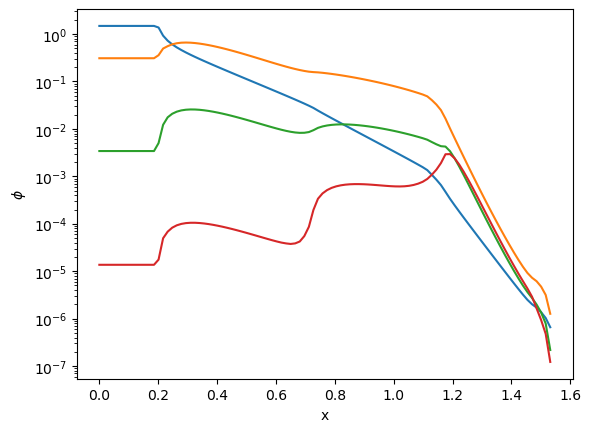

In [88]:
from breeding_blanket_setup import plot_solution_values

plot_solution_values(get_solution_domain(operator_parametrisation.to_module(values_init), solution_domain.element), multigroup_objective.solution(values_init).value)

In [62]:
print(bb_args_1D)

dim = 1
degree= 6
print(bb_args_1D)
region_sizes = [0.2,0.002,0.025,1.0,  0.385, 0.06, 0.25,0.06]
region_resolutions = bb_args_1D[3]
d_other_dim = 5.0
n_other_dim = 1.0
tn_order = 3

MGOP2, source_total2, solution_domain2 = _setup_bb_args(dim, degree, region_sizes, region_resolutions, d_other_dim, n_other_dim, tn_order)

(1, 7, [0.2, 0.002, 0.025, 0.5, 0.385, 0.06, 0.2, 0.06], [5, 1, 1, 5, 5, 1, 5, 2], 5.0, 1, 3)
(1, 7, [0.2, 0.002, 0.025, 0.5, 0.385, 0.06, 0.2, 0.06], [5, 1, 1, 5, 5, 1, 5, 2], 5.0, 1, 3)


In [63]:
from jax_sn.operators.multi_group_operator.multi_group_operator_imp import _solve_multigroup_operator_rhs_scan

result2 = _solve_multigroup_operator_rhs_scan(MGOP2, jnp.stack([source_total2 if i==0 else jnp.zeros_like(source_total2) for i in range(MGOP2.n_energy_groups)]), MultiGroupLowerTriangularBlockSolver(lx.BiCGStab(1e-12,1e-12, max_steps= 100))).value

In [64]:
onp.testing.assert_allclose(result2, solution_value)

NameError: name 'solution_value' is not defined